<a href="https://colab.research.google.com/github/anand7114/API/blob/main/Copy_of_Untitled13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display the CSV files uploaded to Colab
csv_files = glob.glob("/content/*.csv")

print("Available CSV files:")
for file in csv_files:
    print(os.path.basename(file))

# Prefer the balanced binary diabetes dataset
filename = next(
    (
        f for f in csv_files
        if "diabetes_binary_5050split" in os.path.basename(f).lower()
    ),
    None
)

if filename is None:
    raise FileNotFoundError(
        "The diabetes_binary_5050split CSV was not found. "
        "Check the filenames printed above."
    )

df = pd.read_csv(filename)

print("\nDataset loaded:", os.path.basename(filename))
print("Dataset shape:", df.shape)

display(df.head())

Available CSV files:
diabetes_012_health_indicators_BRFSS2015.csv
diabetes_binary_5050split_health_indicators_BRFSS2015.csv
diabetes_binary_health_indicators_BRFSS2015.csv

Dataset loaded: diabetes_binary_5050split_health_indicators_BRFSS2015.csv
Dataset shape: (70692, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [ ]:
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nStatistical summary:")
display(df.describe().T)

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

Rows and columns: (70692, 22)

Column names:
['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Data types:
Diabetes_binary         float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education             

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,70692.0,0.500000,0.500004,0.0,0.0,0.5,1.0,1.0
HighBP,70692.0,0.563458,0.495960,0.0,0.0,1.0,1.0,1.0
HighChol,70692.0,0.525703,0.499342,0.0,0.0,1.0,1.0,1.0
CholCheck,70692.0,0.975259,0.155336,0.0,1.0,1.0,1.0,1.0
BMI,70692.0,29.856985,7.113954,12.0,25.0,29.0,33.0,98.0
Smoker,70692.0,0.475273,0.499392,0.0,0.0,0.0,1.0,1.0
Stroke,70692.0,0.062171,0.241468,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,70692.0,0.147810,0.354914,0.0,0.0,0.0,0.0,1.0
PhysActivity,70692.0,0.703036,0.456924,0.0,0.0,1.0,1.0,1.0
Fruits,70692.0,0.611795,0.487345,0.0,0.0,1.0,1.0,1.0



Missing values:


,Missing Values
Diabetes_binary,0
HighBP,0
HighChol,0
CholCheck,0
BMI,0
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,0
Fruits,0



Duplicate rows: 1635


Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64


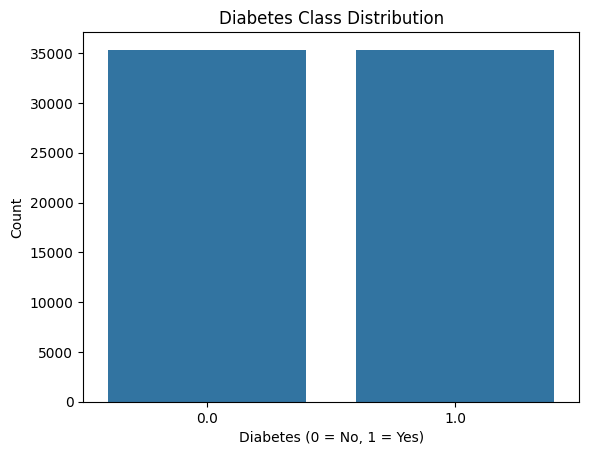

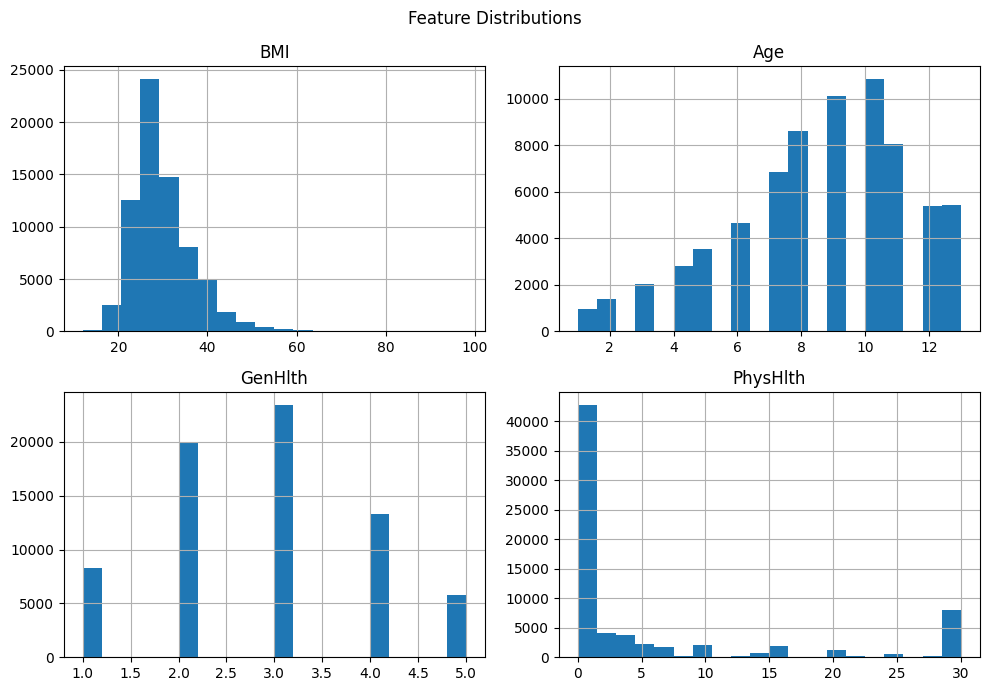

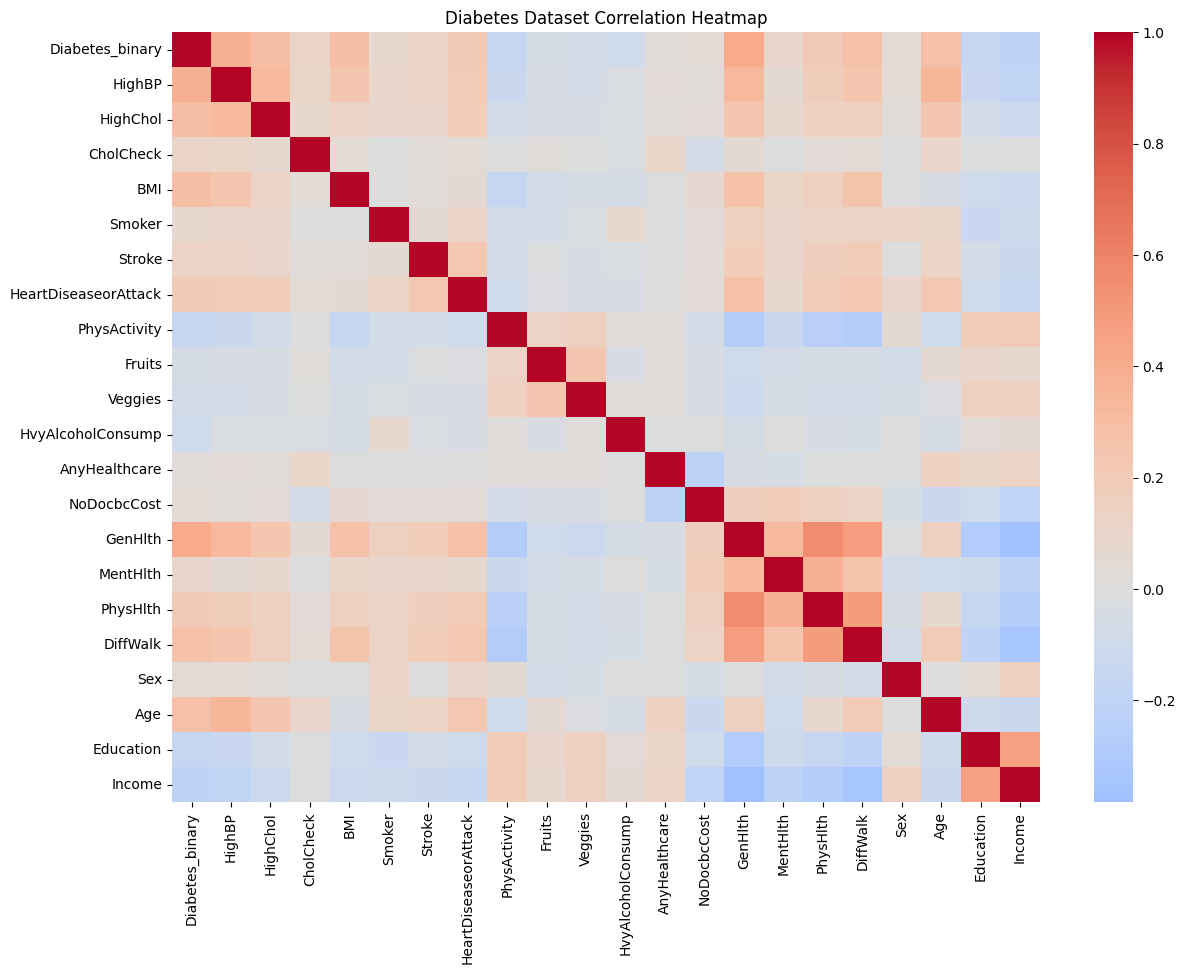

In [ ]:
# Target distribution
print(df["Diabetes_binary"].value_counts())

sns.countplot(data=df, x="Diabetes_binary")
plt.title("Diabetes Class Distribution")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

# Example feature distributions
features = [
    c for c in ["BMI", "Age", "GenHlth", "PhysHlth"]
    if c in df.columns
]

df[features].hist(figsize=(10, 7), bins=20)
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Diabetes Dataset Correlation Heatmap")
plt.show()



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Remove duplicates
df = df.drop_duplicates().copy()

# Separate features and target
X = df.drop(columns=["Diabetes_binary"]).copy()
y = df["Diabetes_binary"].astype(int)

# Convert feature columns to numeric and mark invalid values as missing
X = X.apply(pd.to_numeric, errors="coerce")

# Use up to 6,000 examples from each class for faster SVM training
# The complete dataset remains available in df for EDA.
n_per_class = min(6000, int(y.value_counts().min()))

sample_df = (
    df.groupby("Diabetes_binary", group_keys=False)
      .sample(n=n_per_class, random_state=42)
      .reset_index(drop=True)
)

X = sample_df.drop(columns=["Diabetes_binary"]).apply(
    pd.to_numeric, errors="coerce"
)
y = sample_df["Diabetes_binary"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (9600, 21)
Testing data: (2400, 21)


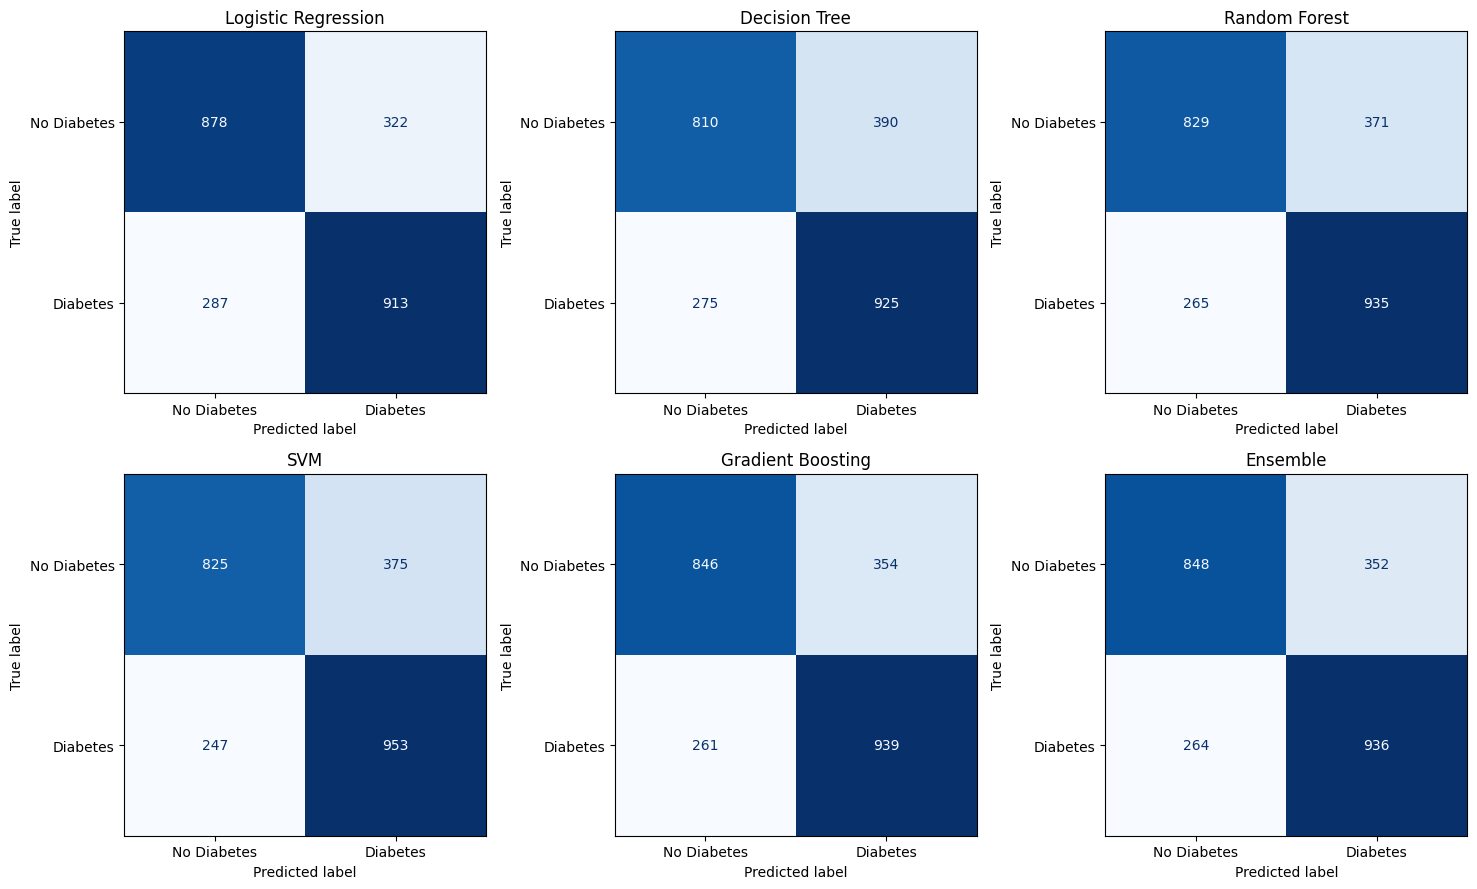

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, model) in zip(axes.ravel(), all_models.items()):
    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["No Diabetes", "Diabetes"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [ ]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1500))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=8, random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(random_state=42))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")


Logistic Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully
SVM trained successfully
Gradient Boosting trained successfully


In [ ]:
ensemble = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("svm", models["SVM"]),
        ("gb", models["Gradient Boosting"])
    ],
    voting="soft"
)

ensemble.fit(X_train, y_train)

print("Ensemble model trained successfully!")

Ensemble model trained successfully!


In [ ]:
all_models = {
    **models,
    "Ensemble": ensemble
}

results = []

for name, model in all_models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7462,0.7393,0.7608,0.7499,0.8174
1,Decision Tree,0.7229,0.7034,0.7708,0.7356,0.7811
2,Random Forest,0.7350,0.7159,0.7792,0.7462,0.8062
3,SVM,0.7408,0.7176,0.7942,0.7540,0.8166
4,Gradient Boosting,0.7438,0.7262,0.7825,0.7533,0.8222
5,Ensemble,0.7433,0.7267,0.7800,0.7524,0.8237


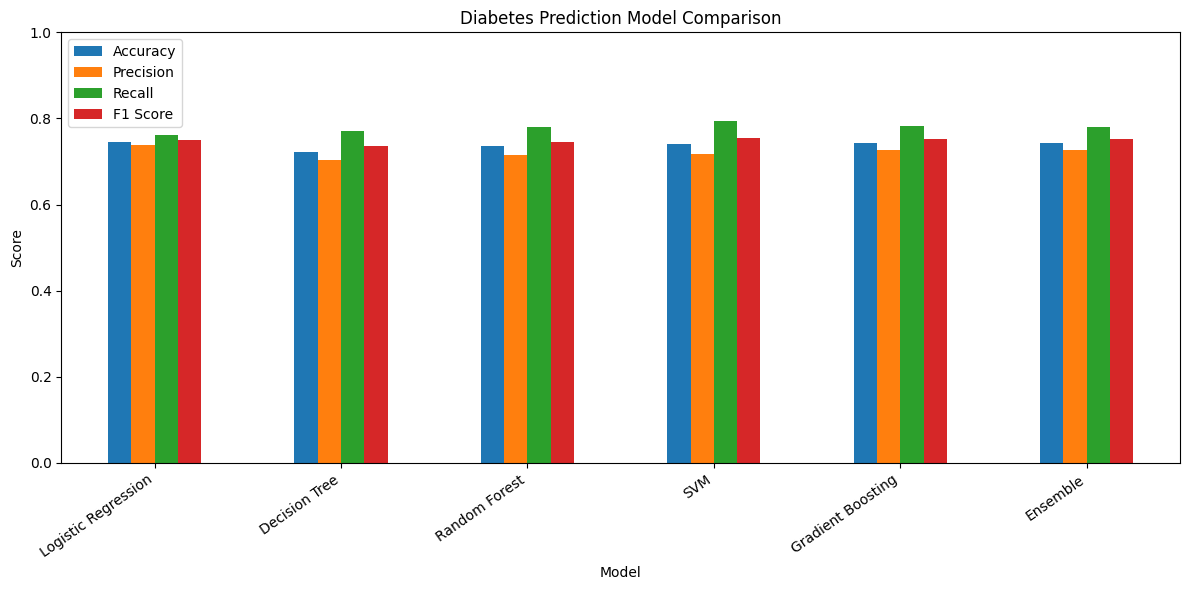

In [ ]:
# Visual comparison
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Diabetes Prediction Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()
